In [2]:
# Importing the required libraries
from cuqi.distribution import Gaussian
from cuqi.problem import BayesianProblem
from cuqi.model import LinearModel
from cuqi.utilities import plot_1D_density, plot_2D_density
import numpy as np
import matplotlib.pyplot as plt

c:\Users\jeppe\Documents\MEGA\Base\DTU\02624 Inverse Problems and Imaging\.venv\Lib\site-packages\cuqi\data\_data.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [3]:
# Forward Model
A_matrix = np.array([[1.0, 1.0]])
A = LinearModel(A_matrix)
display(A)

CUQI LinearModel: _DefaultGeometry1D[2] -> _DefaultGeometry1D[1].
    Forward parameters: ['x'].

(-5.0, 5.0)

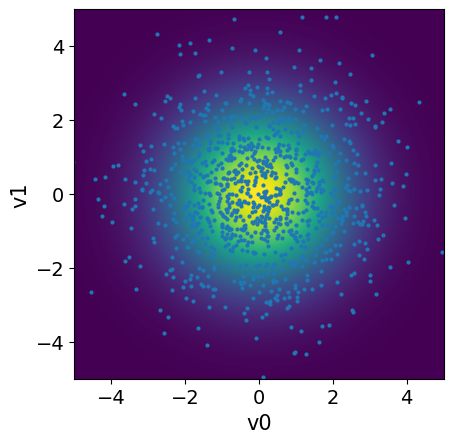

In [4]:
# Set up prior
x = Gaussian(np.zeros(2), 2.5)

# Plot PDF of prior
plot_2D_density(x, v1_min=-5, v1_max=5, v2_min=-5, v2_max=5)

# Sample some points from prior
x_samples = x.sample(1000)

# Plot samples from prior
x_samples.plot_pair(ax=plt.gca())
plt.xlim(-5, 5)
plt.ylim(-5, 5)

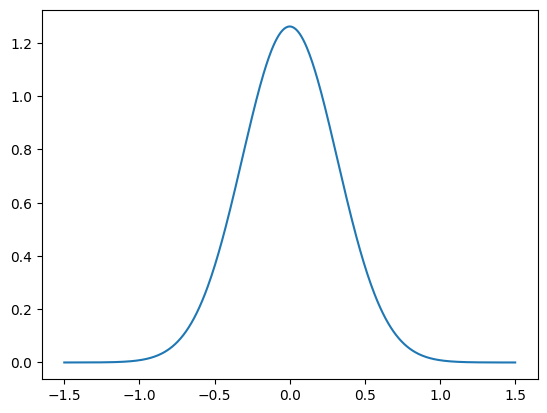

In [5]:
# Add noise
e = Gaussian(0, 0.1)
plot_1D_density(e, v_min=-1.5, v_max=1.5)

3.145540501553451


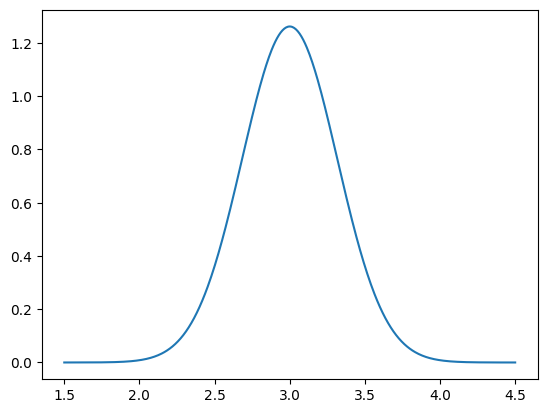

In [12]:
# Posterior
# This is conditional on x
b = Gaussian(A @ x, 0.1)

# Get point from x
particular_x = np.array([1.5, 1.5])

# Get conditional posterior
b_given_particular_x = b(x=particular_x)
plot_1D_density(b_given_particular_x, v_min=1.5, v_max=4.5)

# Get sample from posterior given true x
b_obs = b_given_particular_x.sample()
print(b_obs)

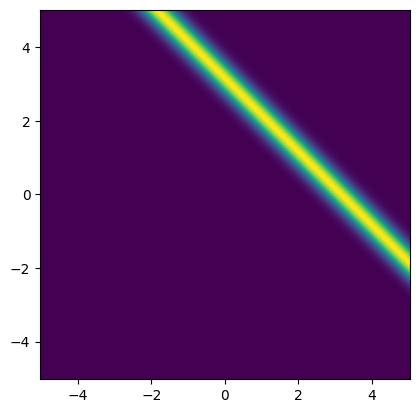

In [ ]:
# Likelihood
likelihood = b(b=b_obs)

x1_lim = np.array([-5, 5])
x2_lim = np.array([-5, 5])
plot_2D_density(
    likelihood, v1_min=x1_lim[0], v1_max=x1_lim[1], v2_min=x2_lim[0], v2_max=x2_lim[1]
)

(-5.0, 5.0)

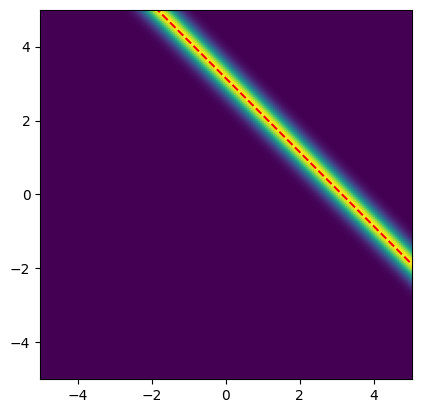

In [16]:
# Maximum likelihood estimate
plot_2D_density(
    likelihood, v1_min=x1_lim[0], v1_max=x1_lim[1], v2_min=x2_lim[0], v2_max=x2_lim[1]
)

# Here maximum likelihood is given by all (x_1, x_2) pairs that satisfy x_1 + x_2 = b_obs
plt.plot(x1_lim, b_obs - x1_lim, 'r--', label=r'$x_1 + x_2 = b_{obs}$')
plt.ylim(x2_lim)

In [ ]:
# Constructing the Bayesian Problem
BP = BayesianProblem(b, x)
print(BP)

# Set observation
BP.set_data(b=b_obs)


BayesianProblem with target: 
 JointDistribution(
    Equation: 
	p(b,x) = p(b|x)p(x)
    Densities: 
	b ~ CUQI Gaussian. Conditioning variables ['x'].
	x ~ CUQI Gaussian.
 )


BayesianProblem with target: 
 Posterior(
    Equation:
	 p(x|b) ∝ L(x|b)p(x)
    Densities:
	b ~ CUQI Gaussian Likelihood function. Parameters ['x'].
 	x ~ CUQI Gaussian.
 )

In [20]:
# Get MAP estimate
map_estimate = BP.MAP()
print("MAP estimate:", map_estimate)

!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
!!! Automatic solver selection is a work-in-progress !!!
!!!      Always validate the computed results.       !!!
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

Using direct MAP of Gaussian posterior. Only works for small-scale problems with dim<=2000.
MAP estimate: [1.54193162 1.54193162]


!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
!!! Automatic sampler selection is a work-in-progress. !!!
!!!       Always validate the computed results.        !!!
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
!!!  Using samplers from cuqi.experimental.mcmc  !!!
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

Using direct sampling of Gaussian posterior. Only works for small-scale problems with dim<=2000.
No burn-in needed for direct sampling.
 Sample 1000 / 1000
Elapsed time: 0.005323648452758789


(-5.0, 5.0)

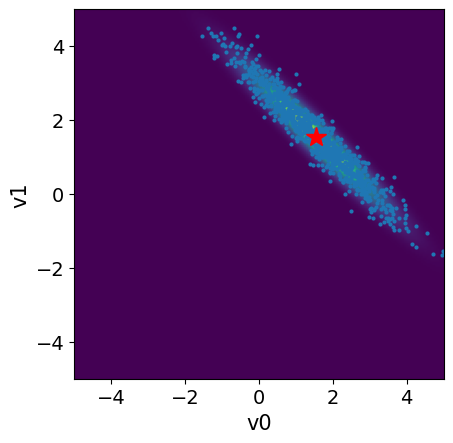

In [24]:
# We want to explore not just a point estimate, but its density
samples = BP.sample_posterior(1000, experimental=True)

# Plot posterior PDF
plot_2D_density(BP.posterior, v1_min=x1_lim[0], v1_max=x1_lim[1], v2_min=x2_lim[0], v2_max=x2_lim[1])

# Plot samples
samples.plot_pair(ax=plt.gca())

# Plot MAP
plt.plot(map_estimate[0], map_estimate[1], 'r*', markersize=15, label='MAP')
plt.xlim(x1_lim)
plt.ylim(x2_lim)